In [43]:
## Code to read in the final models and assess variable contributions etc. ##

# Load in the required packages 

# Read in the packages to use
import numpy as np
import pandas as pd
import math
import datetime
import os
import pathlib
import matplotlib.pyplot as plt
import earthpy as et
import pickle
import random    

from sklearn.model_selection import GridSearchCV                      #for cross validation
from sklearn.feature_selection import RFE                             #for selecting features for the linear reg
from sklearn.model_selection import cross_val_score                   #for cross validation
from sklearn.model_selection import KFold                            
from sklearn.model_selection import GridSearchCV 
from sklearn.preprocessing import StandardScaler                      #for normalising the data
from sklearn.metrics import r2_score                                  #metrics for assessing model
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import StratifiedShuffleSplit
import statsmodels.api as sm                                          #stats models to get linear reg p-values
from statsmodels.tools.eval_measures import rmse                      #calc rmse from stats models
import itertools                                                      #for calculating possible combinations of variables
from sklearn.preprocessing import PolynomialFeatures                  #for polynomial regression
from sklearn.pipeline import make_pipeline             
from xgboost import XGBRegressor

import pvlib
import pytz

# load in the training data:
parent_folder = r"C:/Users/Sarah/Documents/Python_Scripts/DDL/Sensor_Network/Heat_model_Durham_Raleigh/"
train_data_path = os.path.join(parent_folder,"data/joined_data/ERA5_everyday_merged.csv")
data = pd.read_csv(train_data_path)

# sensor info - landcover type and shading scenario
sensor_info_path= r"C:\Users\Sarah\Documents\Python_Scripts\DDL\Sensor_Network\Heat_model_Durham_Raleigh\data\Installed Sensors_0.csv"
sensor_info = pd.read_csv(sensor_info_path)
landcover_shading_info = sensor_info.rename(columns = {'Sensor Serial Number':'Sensor_ID'})[['Sensor_ID','Landcover Type','Shade Type']]
data = data.merge(landcover_shading_info, on = 'Sensor_ID', how ='left')

# add in variable -- SVFs from the fisheye photos
fisheye_data_path = r"C:\Users\Sarah\Documents\Python_Scripts\DDL\Sensor_Network\Heat_model_Durham_Raleigh\data\Fisheye_Data\skyview_factors.csv"
fisheye_data = pd.read_csv(fisheye_data_path)
data = data.merge(fisheye_data[['Sensor_ID','SVF']], on = 'Sensor_ID', how = 'left')


### ----- Pre-clean -------
# fill 0 to categorical vars
# data.fillna(data.mean(),inplace = True)
# Create Cyclical Features for custom hour
#data.dropna(subset = ["Temperature"],inplace = True)
# Convert hours and minutes to total minutes since midnight
data['Hour'] = pd.to_datetime(data['Hour'], format='%H' )
data['Hour'] = data['Hour'].dt.hour
data['Total_Minutes'] = data['Hour'] * 60

# Create cyclical features using sine and cosine transformations
data['sin_time'] = np.sin(2 * np.pi * data['Total_Minutes'] / 1440)  # 1440 = total minutes in a day
data['cos_time'] = np.cos(2 * np.pi * data['Total_Minutes'] / 1440)

# get the zenith angle 
# convert to UTC for use in pvlib 
data['edt_datetime'] = pd.to_datetime(data['edt_datetime']).dt.tz_localize('US/Eastern')
data['utc_datetime'] = data['edt_datetime'].dt.tz_convert('UTC')
durham_lat = 35.99260
durham_lon = -78.89892
# calc solar positions
solpos = pvlib.solarposition.get_solarposition(
    time=data['utc_datetime'],
    latitude=durham_lat,
    longitude=durham_lon
)

# Add zenith angle to data 
data['zenith_angle'] = solpos['zenith'].values

# add in a temperature anomomly quantification to try as target variable (remove diurnal cycle)
data['temp_anom'] = data['Temperature'] - data['temperature_2m'] 
data['rh_anom'] = data['Relative_Humidity'] - data['relative_humidity_2m'] 


### --- Define Model specs -----
# define Y and X
group_name = "Sensor_ID"
Y_name = "rh_anom"

# static variables first, then dynamic
X_names_day =[ 'NDBI_2024SummerMosaic',
          'NDVI_2024SummerMosaic', 'ESA_50',  
         'nearest_motorway_thru_primary_dist','NDMI', 'Tree_DSM_SVF','Albedo_2024SummerMosaic',
         'zenith_angle',#'cos_time', 
              'surface_net_thermal_radiation_hourly','surface_solar_radiation_downwards_hourly',
        'surface_thermal_radiation_downwards_hourly',  'surface_solar_radiation_downwards_accumulation',
        'u_component_of_wind_10m',  'v_component_of_wind_10m', 'windspeed_10m', 
        'relative_humidity_2m', 'temperature_2m', 'total_precipitation_hourly',
           ]

X_names_day.append(group_name)
X_names_day.append('Hour') # save hour so can split by this later for analysis

X_names_night =['NDBI_2024SummerMosaic', 'NDVI_2024SummerMosaic', 'ESA_50', 'nearest_motorway_thru_primary_dist',  'zenith_angle',#'cos_time',  
     'surface_net_thermal_radiation_hourly', 'surface_thermal_radiation_downwards_hourly', 'Tree_DSM_SVF', 
     'surface_solar_radiation_downwards_accumulation', 'u_component_of_wind_10m', 'v_component_of_wind_10m',
     'windspeed_10m', 'relative_humidity_2m', 
     'temperature_2m', 'total_precipitation_hourly']

X_names_night.append(group_name)
X_names_night.append('Hour') # save hour so can split by this later for analysis


# determine the train and test based on landcover/ shading scenario, uncomment/ comment to get scenario to test
#to_split_on = 'Landcover Type'
#to_train_on = 'vegetation'
#to_train_on = 'impervious'

to_split_on = 'Shade Type'
#to_train_on = 'shaded'
to_train_on = 'non-shaded'

train_sensor_ids = list(set(data[data[to_split_on] == to_train_on].Sensor_ID))
test_sensor_ids  = list(set(data[data[to_split_on] != to_train_on].Sensor_ID))

# modelling for incoming sol rad (daytime)
data_day = data[data['surface_solar_radiation_downwards_hourly'] > 1].copy().reset_index(drop = True)

# Apply split to full dataset
train_mask_day = data_day['Sensor_ID'].isin(train_sensor_ids)
test_mask_day  = data_day['Sensor_ID'].isin(test_sensor_ids)

y_day = data_day[Y_name].copy()
X_day = data_day[X_names_day].copy()

X_train_day, X_test_day = X_day[train_mask_day].copy(), X_day[test_mask_day].copy()
y_train_day, y_test_day = y_day[train_mask_day].copy(), y_day[test_mask_day].copy()

# copy datasets before removing hour/id for later analysis
train_day_w_hour = X_train_day.copy()
train_day_w_hour['Relative_Humidity'] = y_train_day
test_day_w_hour = X_test_day.copy()
test_day_w_hour['Relative_Humidity'] = y_test_day

# Drop ID/hour cols before modeling
X_train_day.drop(columns=[group_name, 'Hour'], inplace=True)
X_test_day.drop(columns=[group_name, 'Hour'], inplace=True)

#create normalised datasets
scaler = StandardScaler()
X_train_norm_day = pd.DataFrame(scaler.fit_transform(X_train_day.values), columns = X_train_day.columns) #fit and transform
X_test_norm_day = pd.DataFrame(scaler.transform(X_test_day.values), columns = X_test_day.columns) #transform only


# modelling for no incoming sol rad (nighttime)
data_night = data[data['surface_solar_radiation_downwards_hourly'] < 1].copy().reset_index(drop = True)
# Apply split to full dataset
train_mask_night = data_night['Sensor_ID'].isin(train_sensor_ids)
test_mask_night  = data_night['Sensor_ID'].isin(test_sensor_ids)

y_night = data_night[Y_name].copy()
X_night = data_night[X_names_night].copy()

X_train_night, X_test_night = X_night[train_mask_night].copy(), X_night[test_mask_night].copy()
y_train_night, y_test_night = y_night[train_mask_night].copy(), y_night[test_mask_night].copy()

# copy datasets before removing hour/id for later analysis
train_night_w_hour = X_train_night.copy()
train_night_w_hour['Relative_Humidity'] = y_train_night
test_night_w_hour = X_test_night.copy()
test_night_w_hour['Relative_Humidity'] = y_test_night

# Drop ID/hour cols before modeling
X_train_night.drop(columns=[group_name, 'Hour'], inplace=True)
X_test_night.drop(columns=[group_name, 'Hour'], inplace=True)

#create normalised datasets
scaler = StandardScaler()
X_train_norm_night = pd.DataFrame(scaler.fit_transform(X_train_night.values), columns = X_train_night.columns) #fit and transform
X_test_norm_night = pd.DataFrame(scaler.transform(X_test_night.values), columns = X_test_night.columns) #transform only

# function for getting the prediction interval
# y0 is the predicted value for an observation, y is actual values, y_pred is predicted values
def calc_pred_error(y, y_pred):                                       
    mse = mean_squared_error(y, y_pred) # calculate the mean squared error
    n = len(y_pred)
    mean_pred = np.mean(y_pred)
    y_pred_interval = []
    for y0 in y_pred:
        stderr = mse*(1+1/float(n)+(y0 - mean_pred)**2/np.sum((y_pred - mean_pred)**2))
        pred_interval = np.sqrt(stderr)
        y_pred_interval.append(pred_interval)
    return y_pred_interval


print(f"\nTrain sensors: {len(train_sensor_ids)}  Test sensors: {len(test_sensor_ids)}")

## daytime model 
day_xgb_model = XGBRegressor(objective='reg:squarederror', random_state=42,
                             n_estimators =883,max_depth = 8, learning_rate = 0.059,
                             subsample = 0.6,colsample_bytree = 0.61, min_child_weight =17,
                             gamma =  0.001,reg_alpha =0.0001 ,reg_lambda=80) 

day_xgb_model.fit(X_train_norm_day, y_train_day)

y_train_pred_day = day_xgb_model.predict(X_train_norm_day)
y_test_pred_day = day_xgb_model.predict(X_test_norm_day)

# Add city mean back to anomaly predictions
y_test_pred_full_day = y_test_pred_day + data_day[test_mask_day][ "relative_humidity_2m"].values
y_train_pred_full_day = y_train_pred_day + data_day[train_mask_day][ "relative_humidity_2m"].values
# Also get the true "full" Relative_Humiditys
y_test_full_day = y_test_day + data_day[test_mask_day]["relative_humidity_2m"].values
y_train_full_day = y_train_day + data_day[train_mask_day]["relative_humidity_2m"].values


## nighttime model 
night_xgb_model = XGBRegressor(objective='reg:squarederror', random_state=42,
                             n_estimators =700,max_depth = 7, learning_rate = 0.2,
                             subsample = 0.9,colsample_bytree = 0.4, min_child_weight =26,
                             gamma =  0.014,reg_alpha =0.002 ,reg_lambda=57) 

night_xgb_model.fit(X_train_norm_night, y_train_night)

y_train_pred_night = night_xgb_model.predict(X_train_norm_night)
y_test_pred_night = night_xgb_model.predict(X_test_norm_night)

# Add city mean back to anomaly predictions
y_test_pred_full_night = y_test_pred_night + data_night[test_mask_night][ "relative_humidity_2m"].values
y_train_pred_full_night = y_train_pred_night + data_night[train_mask_night][ "relative_humidity_2m"].values
# Also get the true "full" Relative_Humiditys
y_test_full_night = y_test_night + data_night[test_mask_night]["relative_humidity_2m"].values
y_train_full_night = y_train_night + data_night[train_mask_night]["relative_humidity_2m"].values

## Predictions for the entire 24hrs
y_test_pred_24hrs = np.concatenate([y_test_pred_full_day , y_test_pred_full_night])
y_train_pred_24hrs = np.concatenate([y_train_pred_full_day,y_train_pred_full_night])
y_test_24hrs = np.concatenate([y_test_full_day ,y_test_full_night])
y_train_24hrs = np.concatenate([y_train_full_day , y_train_full_night])


# add the data back into the dataframes 
data_night.loc[test_mask_night, 'Predicted_Relative_Humidity'] = y_test_pred_full_night
data_night.loc[train_mask_night, 'Predicted_Relative_Humidity'] = y_train_pred_full_night
data_day.loc[test_mask_day, 'Predicted_Relative_Humidity'] = y_test_pred_full_day
data_day.loc[train_mask_day, 'Predicted_Relative_Humidity'] = y_train_pred_full_day
data_full_24hrs = pd.concat([data_day, data_night])


Train sensors: 19  Test sensors: 20


Training Metrics-- RMSE: 2.138342194615357 R-square: 0.9884076293023623 MAE: 1.4492794338807256
Test Metrics-- RMSE: 6.096388226483738 R-square: 0.8863212507157503 MAE: 4.602214465596539


Text(-0.08, 1, 'b')

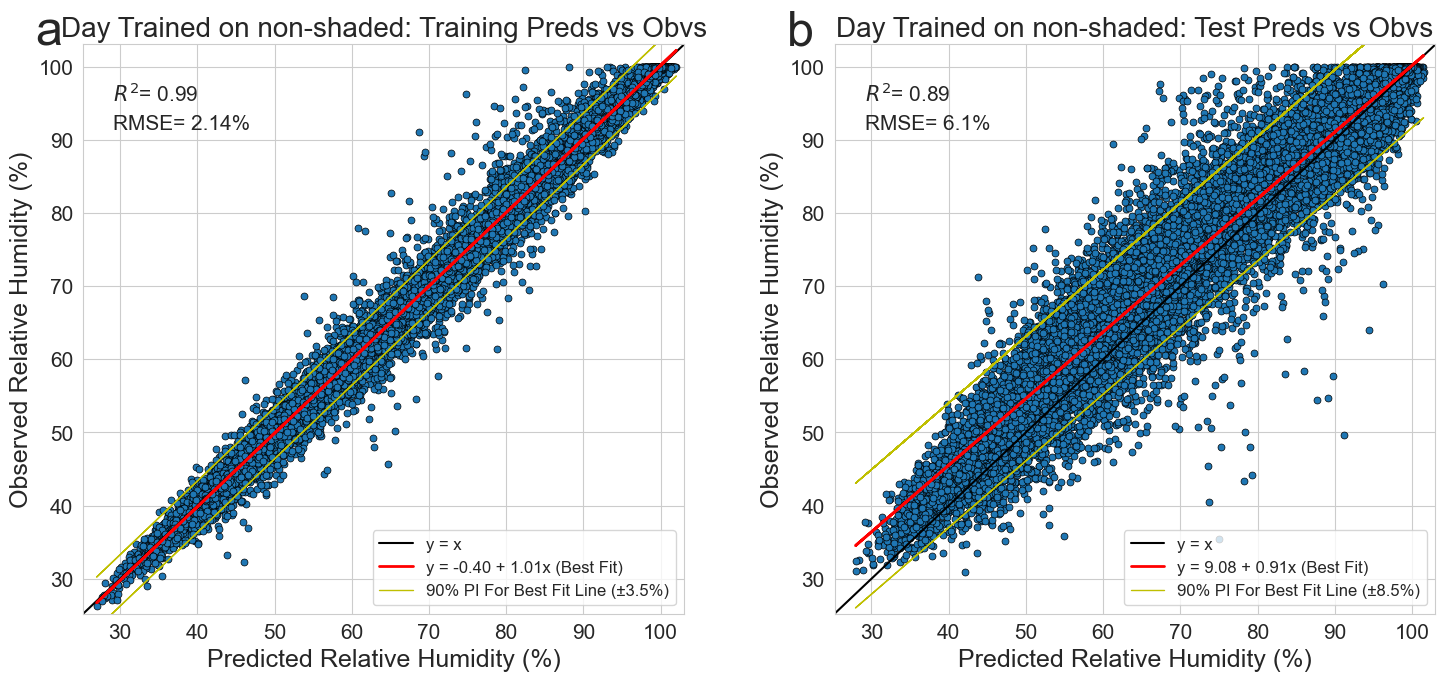

In [44]:
model_name = f'Day Trained on {to_train_on}:'
y_test_pred_full = y_test_pred_full_day
y_train_pred_full = y_train_pred_full_day
y_test_full = y_test_full_day
y_train_full = y_train_full_day

######################################################
###### Performance Metrics for the training set ######
######################################################
#rmse
train_rmse = np.sqrt(mean_squared_error(y_train_full, y_train_pred_full))
#r-square~
train_r2 = r2_score(y_train_full, y_train_pred_full)
#mae
train_mae = mean_absolute_error(y_train_full, y_train_pred_full)
print('Training Metrics--', 'RMSE:', train_rmse, 'R-square:', train_r2, 'MAE:', train_mae)

#################################################
###### Performance Metrics for the test set #####
#################################################
#rmse
test_rmse = np.sqrt(mean_squared_error(y_test_full, y_test_pred_full))
#r-square
test_r2 = r2_score(y_test_full, y_test_pred_full)
#mae
test_mae = mean_absolute_error(y_test_full, y_test_pred_full)
print('Test Metrics--', 'RMSE:', test_rmse, 'R-square:', test_r2, 'MAE:', test_mae)

# PLOTS: obvs vs predictions

#plt.rc('font', size=15)          # controls default text sizes
plt.rc('axes', titlesize=20)     # fontsize of the axes title
plt.rc('axes', labelsize=18)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=15)    # fontsize of the tick labels
plt.rc('ytick', labelsize=15)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize
plt.rc('figure', titlesize=20)  # fontsize of the figure title

# set plot labels
xlab = 'Predicted Relative Humidity (%)'
ylab = 'Observed Relative Humidity (%)'

# set the plot titles
train_title = '{} Training Preds vs Obvs'.format(model_name)
test_title = '{} Test Preds vs Obvs'.format(model_name)
    
# PLOTS: predictions vs obvs with line of best fit 

fig, axes = plt.subplots(1,2, figsize = (16, 8))
fig.tight_layout(pad=7.0)
# training data
axes[0].scatter( y_train_pred_full, y_train_full, s = 25, edgecolors='k', linewidths=0.5)
axes[0].set(title = train_title, 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_train_full), min(y_train_pred_full),min(y_test_full), min(y_test_pred_full)) - 1
axesmax = max(max(y_train_full), max(y_train_pred_full), max(y_test_full), max(y_test_pred_full)) + 1

axes[0].set_xlim([axesmin, axesmax])
axes[0].set_ylim([axesmin, axesmax])
# x = y line
axes[0].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')
# line of best fit
#p, V = np.polyfit(y_train_pred, y_train, 1, cov = True)
#a, b = p[0], p[1]

#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_train_full, sm.add_constant(y_train_pred_full)).fit()
b = sm_model.params.iloc[0]
a = sm_model.params.iloc[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_train_pred_full))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()

axes[0].plot(y_train_pred_full, a*y_train_pred_full+b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

#axes[0].plot(y_train_pred, a*y_train_pred+b + np.std(a*y_train_pred+b), color='r', linestyle='--', 
#             linewidth=1, label = 'Fit std')
#axes[0].plot(y_train_pred, a*y_train_pred+b - np.std(a*y_train_pred+b), color='r', linestyle='--', linewidth=1)


axes[0].plot(y_train_pred_full , pred_interval_lower, color = 'y', linestyle='-', linewidth=1
             ,label = '90% PI For Best Fit Line ({}{:.1f}{})'.format(u'\u00B1',mean_PI,'%'))
axes[0].plot(y_train_pred_full , pred_interval_upper, color = 'y', linestyle='-', linewidth=1)


#text labels
axes[0].text(0.05, 0.9, '$R^2$= {}'.format(round(train_r2, 2)), fontsize=15, transform=axes[0].transAxes)
axes[0].text(0.05, 0.85, 'RMSE= {}%'.format(round(train_rmse, 2)), fontsize=15, transform=axes[0].transAxes)
#axes[0].text(0.05, 0.02, 'y = ' + '{:.2f}'.format(b)+ 
#             ' + {:.2f}'.format(a) + 'x ', 
#             size=15,transform=axes[0].transAxes, color = 'r')

axes[0].legend(loc = 4)
# test data
axes[1].scatter(y_test_pred_full, y_test_full, s = 25, edgecolors='k', linewidths=0.5)
axes[1].set(title = test_title, 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_train_full), min(y_train_pred_full),min(y_test_full), min(y_test_pred_full)) - 1
axesmax = max(max(y_train_full), max(y_train_pred_full), max(y_test_full), max(y_test_pred_full)) + 1

axes[1].set_xlim([axesmin, axesmax])
axes[1].set_ylim([axesmin, axesmax])
axes[1].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')
#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_test_full, sm.add_constant(y_test_pred_full)).fit()
b = sm_model.params.iloc[0]
a = sm_model.params.iloc[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_test_pred_full))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()
pred_interval = calc_pred_error(y_test_full, y_test_pred_full)

#axes[1].scatter(y_test_pred, y_test_pred+pred_interval, s = 25, color = 'orange' , edgecolors='k', linewidths=0.5)

axes[1].plot(y_test_pred_full, a*y_test_pred_full +b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

axes[1].plot(y_test_pred_full , pred_interval_lower, color = 'y', linestyle='-', linewidth=1
            ,label = '90% PI For Best Fit Line ({}{:.1f}{})'.format(u'\u00B1',mean_PI,'%'))
axes[1].plot(y_test_pred_full , pred_interval_upper, color = 'y', linestyle='-', linewidth=1) 


axes[1].legend(loc = 4)

axes[1].text(0.05, 0.9, '$R^2$= {}'.format(round(test_r2, 2)), fontsize=15, transform=axes[1].transAxes)
axes[1].text(0.05, 0.85, 'RMSE= {}%'.format(round(test_rmse, 2)), fontsize=15, transform=axes[1].transAxes)

#add letters for figs
axes[0].text(-0.08, 1, 'a', fontsize=35, transform=axes[0].transAxes)
axes[1].text(-0.08, 1, 'b', fontsize=35, transform=axes[1].transAxes)


Training Metrics-- RMSE: 0.9058734305047118 R-square: 0.9913743778210989 MAE: 0.6516008331285839
Test Metrics-- RMSE: 4.423462326784393 R-square: 0.7937927462436708 MAE: 3.1053253212655747


Text(-0.08, 1, 'b')

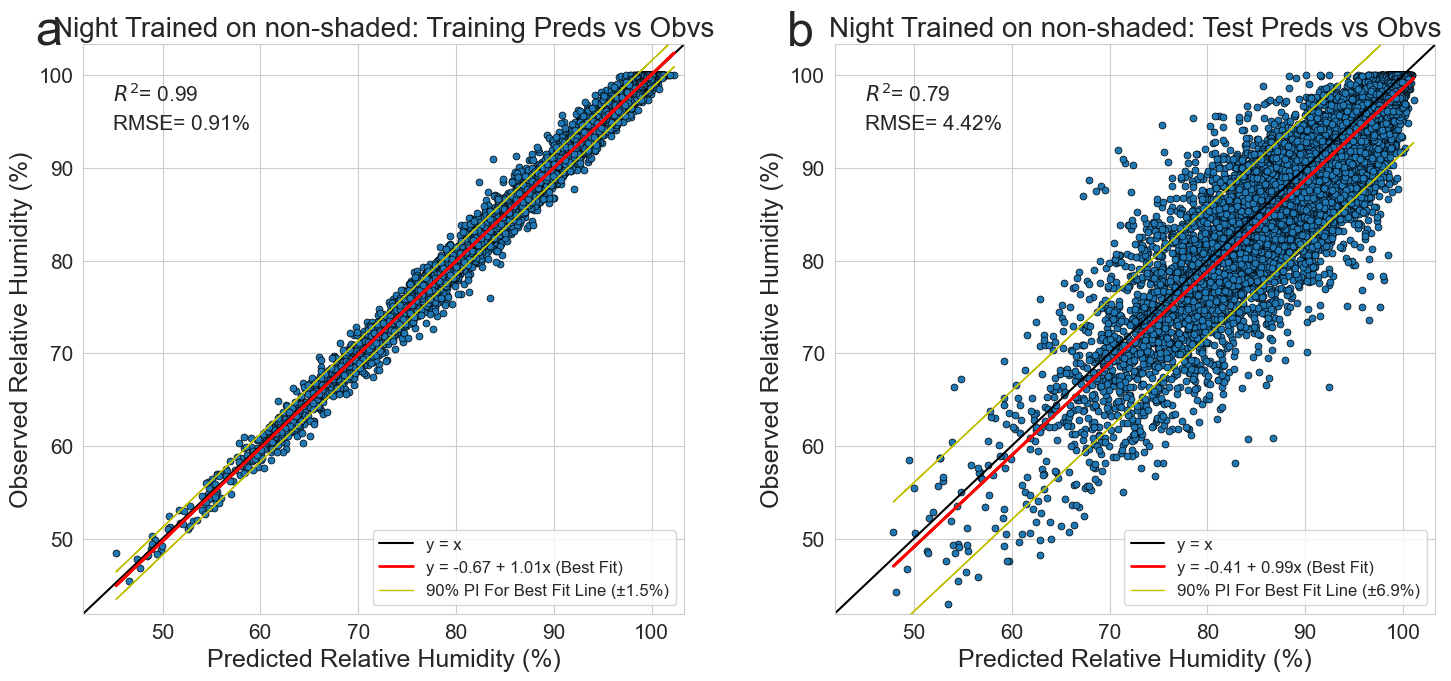

In [45]:
model_name = f'Night Trained on {to_train_on}:'
y_test_pred_full = y_test_pred_full_night
y_train_pred_full = y_train_pred_full_night
y_test_full = y_test_full_night
y_train_full = y_train_full_night

######################################################
###### Performance Metrics for the training set ######
######################################################
#rmse
train_rmse = np.sqrt(mean_squared_error(y_train_full, y_train_pred_full))
#r-square~
train_r2 = r2_score(y_train_full, y_train_pred_full)
#mae
train_mae = mean_absolute_error(y_train_full, y_train_pred_full)
print('Training Metrics--', 'RMSE:', train_rmse, 'R-square:', train_r2, 'MAE:', train_mae)

#################################################
###### Performance Metrics for the test set #####
#################################################
#rmse
test_rmse = np.sqrt(mean_squared_error(y_test_full, y_test_pred_full))
#r-square
test_r2 = r2_score(y_test_full, y_test_pred_full)
#mae
test_mae = mean_absolute_error(y_test_full, y_test_pred_full)
print('Test Metrics--', 'RMSE:', test_rmse, 'R-square:', test_r2, 'MAE:', test_mae)

# PLOTS: obvs vs predictions

#plt.rc('font', size=15)          # controls default text sizes
plt.rc('axes', titlesize=20)     # fontsize of the axes title
plt.rc('axes', labelsize=18)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=15)    # fontsize of the tick labels
plt.rc('ytick', labelsize=15)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize
plt.rc('figure', titlesize=20)  # fontsize of the figure title

# set plot labels
xlab = 'Predicted Relative Humidity (%)'
ylab = 'Observed Relative Humidity (%)'

# set the plot titles
train_title = '{} Training Preds vs Obvs'.format(model_name)
test_title = '{} Test Preds vs Obvs'.format(model_name)
    
# PLOTS: predictions vs obvs with line of best fit 

fig, axes = plt.subplots(1,2, figsize = (16, 8))
fig.tight_layout(pad=7.0)
# training data
axes[0].scatter( y_train_pred_full, y_train_full, s = 25, edgecolors='k', linewidths=0.5)
axes[0].set(title = train_title, 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_train_full), min(y_train_pred_full),min(y_test_full), min(y_test_pred_full)) - 1
axesmax = max(max(y_train_full), max(y_train_pred_full), max(y_test_full), max(y_test_pred_full)) + 1

axes[0].set_xlim([axesmin, axesmax])
axes[0].set_ylim([axesmin, axesmax])
# x = y line
axes[0].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')
# line of best fit
#p, V = np.polyfit(y_train_pred, y_train, 1, cov = True)
#a, b = p[0], p[1]

#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_train_full, sm.add_constant(y_train_pred_full)).fit()
b = sm_model.params.iloc[0]
a = sm_model.params.iloc[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_train_pred_full))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()

axes[0].plot(y_train_pred_full, a*y_train_pred_full+b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

#axes[0].plot(y_train_pred, a*y_train_pred+b + np.std(a*y_train_pred+b), color='r', linestyle='--', 
#             linewidth=1, label = 'Fit std')
#axes[0].plot(y_train_pred, a*y_train_pred+b - np.std(a*y_train_pred+b), color='r', linestyle='--', linewidth=1)


axes[0].plot(y_train_pred_full , pred_interval_lower, color = 'y', linestyle='-', linewidth=1
             ,label = '90% PI For Best Fit Line ({}{:.1f}{})'.format(u'\u00B1',mean_PI,'%'))
axes[0].plot(y_train_pred_full , pred_interval_upper, color = 'y', linestyle='-', linewidth=1)


#text labels
axes[0].text(0.05, 0.9, '$R^2$= {}'.format(round(train_r2, 2)), fontsize=15, transform=axes[0].transAxes)
axes[0].text(0.05, 0.85, 'RMSE= {}%'.format(round(train_rmse, 2)), fontsize=15, transform=axes[0].transAxes)
#axes[0].text(0.05, 0.02, 'y = ' + '{:.2f}'.format(b)+ 
#             ' + {:.2f}'.format(a) + 'x ', 
#             size=15,transform=axes[0].transAxes, color = 'r')

axes[0].legend(loc = 4)
# test data
axes[1].scatter(y_test_pred_full, y_test_full, s = 25, edgecolors='k', linewidths=0.5)
axes[1].set(title = test_title, 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_train_full), min(y_train_pred_full),min(y_test_full), min(y_test_pred_full)) - 1
axesmax = max(max(y_train_full), max(y_train_pred_full), max(y_test_full), max(y_test_pred_full)) + 1

axes[1].set_xlim([axesmin, axesmax])
axes[1].set_ylim([axesmin, axesmax])
axes[1].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')
#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_test_full, sm.add_constant(y_test_pred_full)).fit()
b = sm_model.params.iloc[0]
a = sm_model.params.iloc[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_test_pred_full))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()
pred_interval = calc_pred_error(y_test_full, y_test_pred_full)

#axes[1].scatter(y_test_pred, y_test_pred+pred_interval, s = 25, color = 'orange' , edgecolors='k', linewidths=0.5)

axes[1].plot(y_test_pred_full, a*y_test_pred_full +b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

axes[1].plot(y_test_pred_full , pred_interval_lower, color = 'y', linestyle='-', linewidth=1
            ,label = '90% PI For Best Fit Line ({}{:.1f}{})'.format(u'\u00B1',mean_PI,'%'))
axes[1].plot(y_test_pred_full , pred_interval_upper, color = 'y', linestyle='-', linewidth=1) 


axes[1].legend(loc = 4)

axes[1].text(0.05, 0.9, '$R^2$= {}'.format(round(test_r2, 2)), fontsize=15, transform=axes[1].transAxes)
axes[1].text(0.05, 0.85, 'RMSE= {}%'.format(round(test_rmse, 2)), fontsize=15, transform=axes[1].transAxes)

#add letters for figs
axes[0].text(-0.08, 1, 'a', fontsize=35, transform=axes[0].transAxes)
axes[1].text(-0.08, 1, 'b', fontsize=35, transform=axes[1].transAxes)


Training Metrics-- RMSE: 1.7574428255533106 R-square: 0.9917008562281074 MAE: 1.1337921595097096
Test Metrics-- RMSE: 5.49453442837467 R-square: 0.895163584095577 MAE: 4.008862511184307


Text(-0.08, 1, 'a')

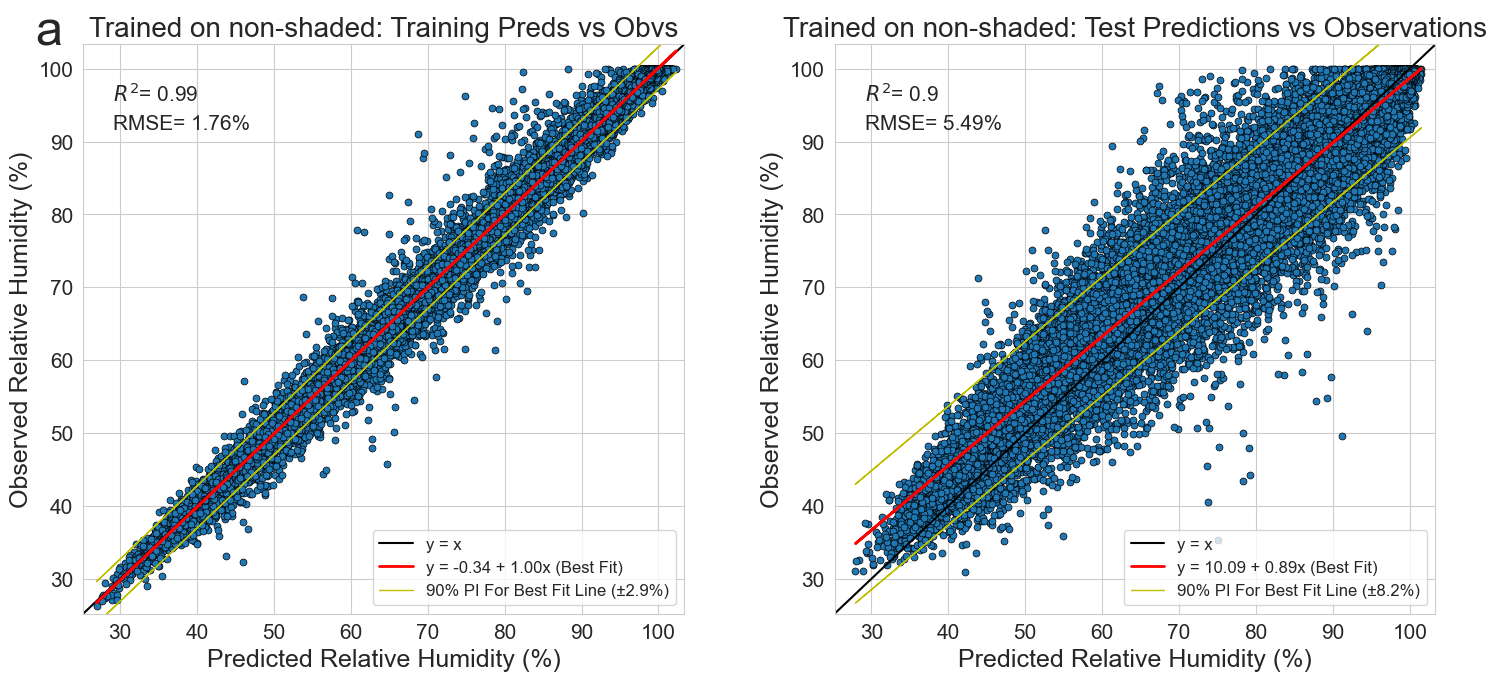

In [46]:
model_name = f'Trained on {to_train_on}:'
y_test_pred_full = y_test_pred_24hrs
y_train_pred_full = y_train_pred_24hrs
y_test_full = y_test_24hrs
y_train_full = y_train_24hrs

######################################################
###### Performance Metrics for the training set ######
######################################################
#rmse
train_rmse = np.sqrt(mean_squared_error(y_train_full, y_train_pred_full))
#r-square~
train_r2 = r2_score(y_train_full, y_train_pred_full)
#mae
train_mae = mean_absolute_error(y_train_full, y_train_pred_full)
print('Training Metrics--', 'RMSE:', train_rmse, 'R-square:', train_r2, 'MAE:', train_mae)

#################################################
###### Performance Metrics for the test set #####
#################################################
#rmse
test_rmse = np.sqrt(mean_squared_error(y_test_full, y_test_pred_full))
#r-square
test_r2 = r2_score(y_test_full, y_test_pred_full)
#mae
test_mae = mean_absolute_error(y_test_full, y_test_pred_full)
print('Test Metrics--', 'RMSE:', test_rmse, 'R-square:', test_r2, 'MAE:', test_mae)

# PLOTS: obvs vs predictions

#plt.rc('font', size=15)          # controls default text sizes
plt.rc('axes', titlesize=20)     # fontsize of the axes title
plt.rc('axes', labelsize=18)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=15)    # fontsize of the tick labels
plt.rc('ytick', labelsize=15)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize
plt.rc('figure', titlesize=20)  # fontsize of the figure title

# set plot labels
xlab = 'Predicted Relative Humidity (%)'
ylab = 'Observed Relative Humidity (%)'

# set the plot titles
train_title = '{} Training Preds vs Obvs'.format(model_name)
test_title = '{} Test Predictions vs Observations'.format(model_name)
    
# PLOTS: predictions vs obvs with line of best fit 

fig, axes = plt.subplots(1,2, figsize = (16, 8))
fig.tight_layout(pad=7.0)
# training data
axes[0].scatter( y_train_pred_full, y_train_full, s = 25, edgecolors='k', linewidths=0.5)
axes[0].set(title = train_title, 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_train_full), min(y_train_pred_full),min(y_test_full), min(y_test_pred_full)) - 1
axesmax = max(max(y_train_full), max(y_train_pred_full), max(y_test_full), max(y_test_pred_full)) + 1

axes[0].set_xlim([axesmin, axesmax])
axes[0].set_ylim([axesmin, axesmax])
# x = y line
axes[0].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')
# line of best fit
#p, V = np.polyfit(y_train_pred, y_train, 1, cov = True)
#a, b = p[0], p[1]

#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_train_full, sm.add_constant(y_train_pred_full)).fit()
b = sm_model.params[0]
a = sm_model.params[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_train_pred_full))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()

axes[0].plot(y_train_pred_full, a*y_train_pred_full+b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

#axes[0].plot(y_train_pred, a*y_train_pred+b + np.std(a*y_train_pred+b), color='r', linestyle='--', 
#             linewidth=1, label = 'Fit std')
#axes[0].plot(y_train_pred, a*y_train_pred+b - np.std(a*y_train_pred+b), color='r', linestyle='--', linewidth=1)


axes[0].plot(y_train_pred_full , pred_interval_lower, color = 'y', linestyle='-', linewidth=1
             ,label = '90% PI For Best Fit Line ({}{:.1f}{})'.format(u'\u00B1',mean_PI,'%'))
axes[0].plot(y_train_pred_full , pred_interval_upper, color = 'y', linestyle='-', linewidth=1)


#text labels
axes[0].text(0.05, 0.9, '$R^2$= {}'.format(round(train_r2, 2)), fontsize=15, transform=axes[0].transAxes)
axes[0].text(0.05, 0.85, 'RMSE= {}%'.format(round(train_rmse, 2)), fontsize=15, transform=axes[0].transAxes)
#axes[0].text(0.05, 0.02, 'y = ' + '{:.2f}'.format(b)+ 
#             ' + {:.2f}'.format(a) + 'x ', 
#             size=15,transform=axes[0].transAxes, color = 'r')

axes[0].legend(loc = 4)
# test data
axes[1].scatter(y_test_pred_full, y_test_full, s = 25, edgecolors='k', linewidths=0.5)
axes[1].set(title = test_title, 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_train_full), min(y_train_pred_full),min(y_test_full), min(y_test_pred_full)) - 1
axesmax = max(max(y_train_full), max(y_train_pred_full), max(y_test_full), max(y_test_pred_full)) + 1

axes[1].set_xlim([axesmin, axesmax])
axes[1].set_ylim([axesmin, axesmax])
axes[1].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')
#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_test_full, sm.add_constant(y_test_pred_full)).fit()
b = sm_model.params[0]
a = sm_model.params[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_test_pred_full))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()
pred_interval = calc_pred_error(y_test_full, y_test_pred_full)

#axes[1].scatter(y_test_pred, y_test_pred+pred_interval, s = 25, color = 'orange' , edgecolors='k', linewidths=0.5)

axes[1].plot(y_test_pred_full, a*y_test_pred_full +b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

axes[1].plot(y_test_pred_full , pred_interval_lower, color = 'y', linestyle='-', linewidth=1
            ,label = '90% PI For Best Fit Line ({}{:.1f}{})'.format(u'\u00B1',mean_PI,'%'))
axes[1].plot(y_test_pred_full , pred_interval_upper, color = 'y', linestyle='-', linewidth=1) 


axes[1].legend(loc = 4)

axes[1].text(0.05, 0.9, '$R^2$= {}'.format(round(test_r2, 2)), fontsize=15, transform=axes[1].transAxes)
axes[1].text(0.05, 0.85, 'RMSE= {}%'.format(round(test_rmse, 2)), fontsize=15, transform=axes[1].transAxes)

#add letters for figs
axes[0].text(-0.08, 1, 'a', fontsize=35, transform=axes[0].transAxes)
#axes[1].text(-0.08, 1, 'b', fontsize=35, transform=axes[1].transAxes)


In [47]:
import seaborn as sns

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17],
 [Text(0, 0, 'surface_solar_radiation_downwards_accumulation'),
  Text(0, 1, 'relative_humidity_2m'),
  Text(0, 2, 'NDVI_2024SummerMosaic'),
  Text(0, 3, 'temperature_2m'),
  Text(0, 4, 'surface_thermal_radiation_downwards_hourly'),
  Text(0, 5, 'surface_net_thermal_radiation_hourly'),
  Text(0, 6, 'NDBI_2024SummerMosaic'),
  Text(0, 7, 'total_precipitation_hourly'),
  Text(0, 8, 'v_component_of_wind_10m'),
  Text(0, 9, 'NDMI'),
  Text(0, 10, 'u_component_of_wind_10m'),
  Text(0, 11, 'zenith_angle'),
  Text(0, 12, 'surface_solar_radiation_downwards_hourly'),
  Text(0, 13, 'windspeed_10m'),
  Text(0, 14, 'Tree_DSM_SVF'),
  Text(0, 15, 'Albedo_2024SummerMosaic'),
  Text(0, 16, 'nearest_motorway_thru_primary_dist'),
  Text(0, 17, 'ESA_50')])

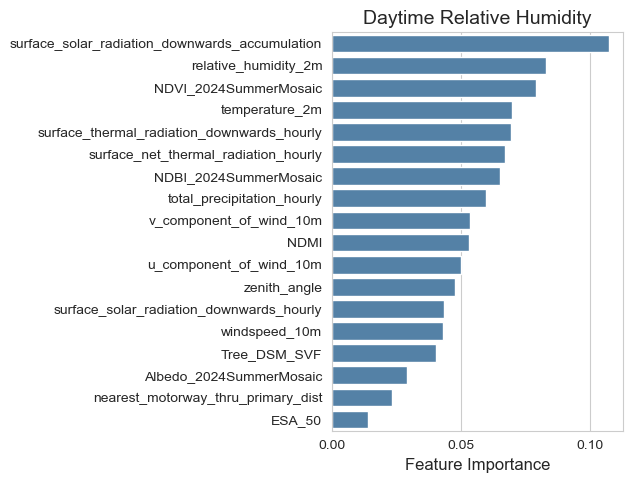

In [48]:
# Get feature importances
importances = day_xgb_model.feature_importances_

# Put into a dataframe for readability
feat_importances = pd.DataFrame({
    "Feature": X_train_norm_day.columns,
    "Importance_RH_Day": importances
}).sort_values(by="Importance_RH_Day", ascending=False)

feat_importances.to_csv('feat_importances_RH_Day.csv', index = False)
#print(feat_importances)

plt.figure(figsize=(8, 5))
sns.set_style("whitegrid")
sns.barplot(
    data=feat_importances,
    y="Feature",                 
    x="Importance_RH_Day",
    color="steelblue"
)

plt.xlabel("Feature Importance", fontsize=12)
plt.ylabel("")                 
plt.title("Daytime Relative Humidity", fontsize=14)#, weight='bold')
plt.tight_layout()

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

#plt.savefig('results/rh_day_rel_imp.png',transparent=True)

In [49]:
feat_importances

,Feature,Importance_RH_Day
11,surface_solar_radiation_downwards_accumulation,0.107652
15,relative_humidity_2m,0.083126
1,NDVI_2024SummerMosaic,0.079110
16,temperature_2m,0.069746
10,surface_thermal_radiation_downwards_hourly,0.069658
8,surface_net_thermal_radiation_hourly,0.067089
0,NDBI_2024SummerMosaic,0.065155
17,total_precipitation_hourly,0.059883
13,v_component_of_wind_10m,0.053626
4,NDMI,0.053338


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
 [Text(0, 0, 'surface_solar_radiation_downwards_accumulation'),
  Text(0, 1, 'relative_humidity_2m'),
  Text(0, 2, 'surface_thermal_radiation_downwards_hourly'),
  Text(0, 3, 'surface_net_thermal_radiation_hourly'),
  Text(0, 4, 'temperature_2m'),
  Text(0, 5, 'total_precipitation_hourly'),
  Text(0, 6, 'zenith_angle'),
  Text(0, 7, 'nearest_motorway_thru_primary_dist'),
  Text(0, 8, 'NDVI_2024SummerMosaic'),
  Text(0, 9, 'v_component_of_wind_10m'),
  Text(0, 10, 'windspeed_10m'),
  Text(0, 11, 'u_component_of_wind_10m'),
  Text(0, 12, 'NDBI_2024SummerMosaic'),
  Text(0, 13, 'ESA_50'),
  Text(0, 14, 'Tree_DSM_SVF')])

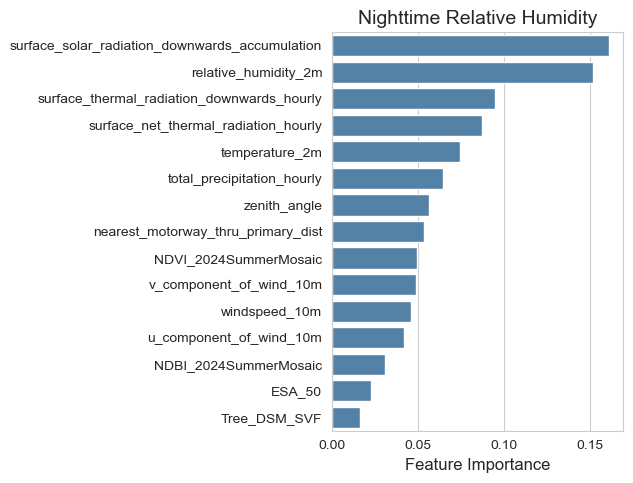

In [50]:
# Get feature importances
importances = night_xgb_model.feature_importances_

# Put into a dataframe for readability
feat_importances_night = pd.DataFrame({
    "Feature": X_train_norm_night.columns,
    "Importance_RH_Night": importances
}).sort_values(by="Importance_RH_Night", ascending=False)

feat_importances_night.to_csv('feat_importances_RH_night.csv', index = False)
#print(feat_importances)
plt.figure(figsize=(8, 5))
sns.set_style("whitegrid")
sns.barplot(
    data=feat_importances_night,
    y="Feature",                 
    x="Importance_RH_Night",
    color="steelblue"
)

plt.xlabel("Feature Importance", fontsize=12)
plt.ylabel("")                 
plt.title("Nighttime Relative Humidity", fontsize=14)#, weight='bold')
plt.tight_layout()

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

#plt.savefig('results/rh_night_rel_imp.png',transparent=True)

In [51]:
# add in RH measurement error

# the RH error is set as 95th percentile of standard error between sensors in calibration experiments 
#Day RH 95th percentile std error 0.36235253201311085
#Night RH 95th percentile std error 0.257524304052384

day_rh_measurement_err = 0.36235
night_rh_measurement_err = 0.2575

data_day['RH_Measurement_CI'] = day_rh_measurement_err
data_night['RH_Measurement_CI'] = night_rh_measurement_err

In [52]:
############### Hourly performance, test data only  ####################
data_all_w_predicted = pd.concat([data_day, data_night])
data_all_w_predicted = data_all_w_predicted[data_all_w_predicted.Sensor_ID.isin(test_sensor_ids)]

In [53]:
data_all_w_predicted

,Temperature,Relative_Humidity,Date,Hour,Sensor_ID,x,y,Albedo_2024SummerMosaic,CDL_org,CDL_121,...,SVF,Total_Minutes,sin_time,cos_time,utc_datetime,zenith_angle,temp_anom,rh_anom,Predicted_Relative_Humidity,RH_Measurement_CI
899,24.083333,97.533333,2024-07-01,7,2401086,-78.906959,35.891580,0.163733,122,0,...,0.234021,420,0.965926,-2.588190e-01,2024-07-01 11:00:00+00:00,80.410078,1.247095,5.596877,96.495957,0.36235
900,21.879630,89.616667,2024-07-01,8,2401086,-78.906959,35.891580,0.163733,122,0,...,0.234021,480,0.866025,-5.000000e-01,2024-07-01 12:00:00+00:00,68.857161,-0.000769,7.597042,91.720767,0.36235
901,21.231481,86.766667,2024-07-01,9,2401086,-78.906959,35.891580,0.163733,122,0,...,0.234021,540,0.707107,-7.071068e-01,2024-07-01 13:00:00+00:00,56.913466,-0.812340,22.270371,88.414505,0.36235
902,21.064815,67.816667,2024-07-01,10,2401086,-78.906959,35.891580,0.163733,122,0,...,0.234021,600,0.500000,-8.660254e-01,2024-07-01 14:00:00+00:00,44.797136,-2.117008,13.644597,73.472953,0.36235
903,22.212963,59.066667,2024-07-01,11,2401086,-78.906959,35.891580,0.163733,122,0,...,0.234021,660,0.258819,-9.659258e-01,2024-07-01 15:00:00+00:00,32.792268,-2.280025,11.664424,59.239665,0.36235
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22189,21.768519,99.233333,2024-08-31,6,2974347,-78.844527,36.011712,0.161167,124,0,...,0.084052,360,1.000000,6.123234e-17,2024-08-31 10:00:00+00:00,100.032245,-0.082710,0.697729,99.659322,0.25750
22190,21.620370,99.233333,2024-08-31,7,2974347,-78.844527,36.011712,0.161167,124,0,...,0.084052,420,0.965926,-2.588190e-01,2024-08-31 11:00:00+00:00,88.252829,-0.127959,0.278893,99.939726,0.25750
22191,25.805556,88.500000,2024-08-31,21,2974347,-78.844527,36.011712,0.161167,124,0,...,0.084052,1260,-0.707107,7.071068e-01,2024-09-01 01:00:00+00:00,105.606812,-0.351516,5.141037,81.269381,0.25750
22192,25.435185,89.633333,2024-08-31,22,2974347,-78.844527,36.011712,0.161167,124,0,...,0.084052,1320,-0.500000,8.660254e-01,2024-09-01 02:00:00+00:00,116.319336,-0.230842,5.969673,86.133300,0.25750


    Hour      RMSE       MAE       MBE   MPE (%)        R²
0      0  4.824048  3.442947  1.397544  1.932265  0.762034
1      1  4.373097  3.130209  1.282448  1.700572  0.762293
2      2  4.218807  2.934956  1.349911  1.717915  0.730878
3      3  4.000458  2.754505  1.409706  1.752764  0.725435
4      4  3.785673  2.626428  1.307128  1.599602  0.723060
5      5  3.635958  2.490238  1.329018  1.579637  0.692737
6      6  3.444918  2.380930  1.327029  1.546750  0.666633
7      7  3.298305  2.310997  1.333003  1.546379  0.671705
8      8  3.292432  2.307855  0.720810  0.897395  0.743367
9      9  5.112071  3.643575 -1.317069 -1.282974  0.666078
10    10  7.585711  5.634946 -4.580935 -5.406161  0.553549
11    11  7.739161  6.234523 -5.675353 -7.537741  0.648287
12    12  7.256847  6.132367 -5.563006 -7.912236  0.732592
13    13  6.856375  5.782600 -5.390564 -8.221016  0.785422
14    14  6.402973  5.408698 -4.738213 -7.455229  0.832588
15    15  6.151843  5.177626 -4.079146 -6.615277  0.8623

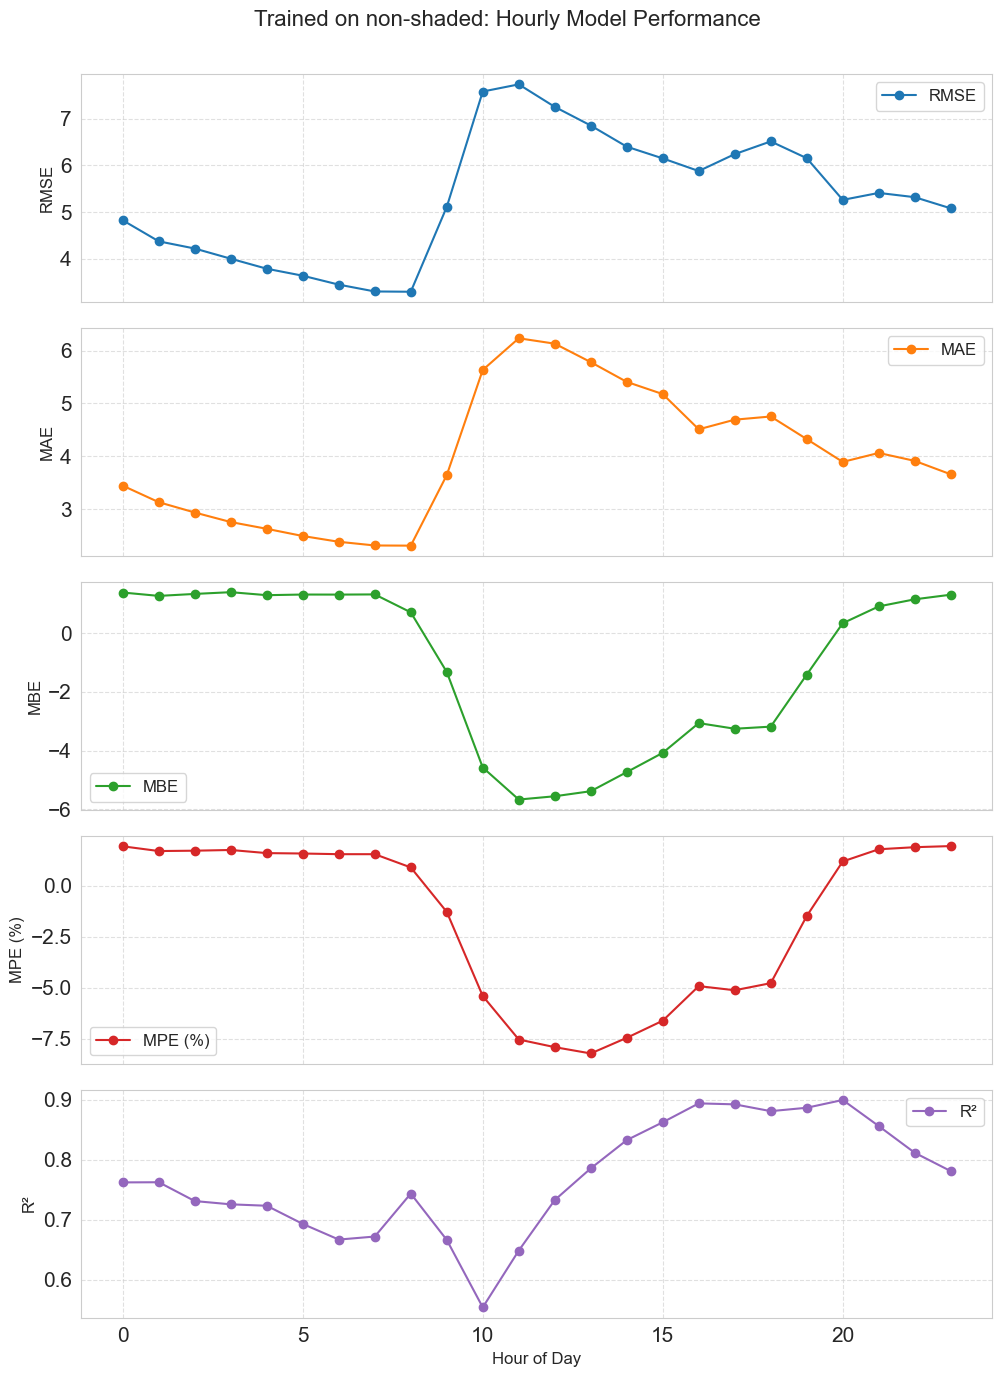

In [54]:

def calc_metrics(obs, pred):
    rmse = np.sqrt(mean_squared_error(obs, pred))
    mae = mean_absolute_error(obs, pred)
    mbe = np.mean(pred - obs)
    mpe = np.mean((pred - obs) / obs) * 100     # %
    r2  = r2_score(obs, pred)
    return rmse, mae, mbe, mpe, r2

# --- Compute hourly metrics ---
hourly_stats = []
for hour, group in data_all_w_predicted.groupby('Hour'):
    rmse, mae, mbe, mpe, r2 = calc_metrics(group['Relative_Humidity'], group['Predicted_Relative_Humidity'])
    hourly_stats.append({
        'Hour': hour,
        'RMSE': rmse,
        'MAE': mae,
        'MBE': mbe,
        'MPE (%)': mpe,
        'R²': r2
    })

hourly_stats_df = pd.DataFrame(hourly_stats).sort_values('Hour')

print(hourly_stats_df)

# --- Create subplots: one subplot for each metric ---
metrics = ['RMSE', 'MAE', 'MBE', 'MPE (%)', 'R²']
colors  = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

fig, axes = plt.subplots(len(metrics), 1, figsize=(10, 14), sharex=True)

for ax, metric, color in zip(axes, metrics, colors):
    ax.plot(hourly_stats_df['Hour'], hourly_stats_df[metric],
            marker='o', color=color, label=metric)
    ax.set_ylabel(metric, fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='best')

axes[-1].set_xlabel('Hour of Day', fontsize=12)
fig.suptitle(f'Trained on {to_train_on}: Hourly Model Performance', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
hourly_stats_df.to_csv(f'results/RH_hourly_test_data_stats_{to_train_on}.csv', index = False)


In [55]:
data_all_w_predicted = pd.concat([data_day, data_night])
data_all_w_predicted = data_all_w_predicted[data_all_w_predicted.Sensor_ID.isin(test_sensor_ids)]
# Calculate residuals
data_all_w_predicted['residual'] = (
    data_all_w_predicted['Relative_Humidity'] - data_all_w_predicted['Predicted_Relative_Humidity']
)

# Define desired confidence level
#alpha = 0.05    # for 95% prediction interval
alpha = 0.1    # for 90% prediction interval

# --- Compute fixed residual quantiles for each hour across all days ---
hourly_residual_q = (
    data_all_w_predicted
    .groupby('Hour')['residual']
    .quantile([alpha/2, 1 - alpha/2])
    .unstack()
    .rename(columns={alpha/2: 'lower_residual_q', 1 - alpha/2: 'upper_residual_q'})
    .reset_index()
)

# Merge these hourly quantiles back into main DataFrame
data_all_w_predicted = data_all_w_predicted.merge(hourly_residual_q, on='Hour', how='left')

# Compute PIs using the *fixed hourly quantiles*
data_all_w_predicted['PI_lower'] = (
    data_all_w_predicted['Predicted_Relative_Humidity'] + data_all_w_predicted['lower_residual_q']
)
data_all_w_predicted['PI_upper'] = (
    data_all_w_predicted['Predicted_Relative_Humidity'] + data_all_w_predicted['upper_residual_q']
)
data_all_w_predicted['Measurement_CI_lower'] = (
    data_all_w_predicted['PI_lower'] - data_all_w_predicted['RH_Measurement_CI']
)
data_all_w_predicted['Measurement_CI_upper'] = (
    data_all_w_predicted['PI_upper'] + data_all_w_predicted['RH_Measurement_CI']
)
# --- Prepare an hourly summary for plotting ---
hourly_summary = (
    data_all_w_predicted
    .groupby('Hour')
    .agg({
        'Relative_Humidity': 'mean',
        'Predicted_Relative_Humidity': 'mean',
        'PI_lower': 'mean',
        'PI_upper': 'mean',
        'Measurement_CI_lower':'mean',
        'Measurement_CI_upper':'mean',
    })
    .reset_index()
)



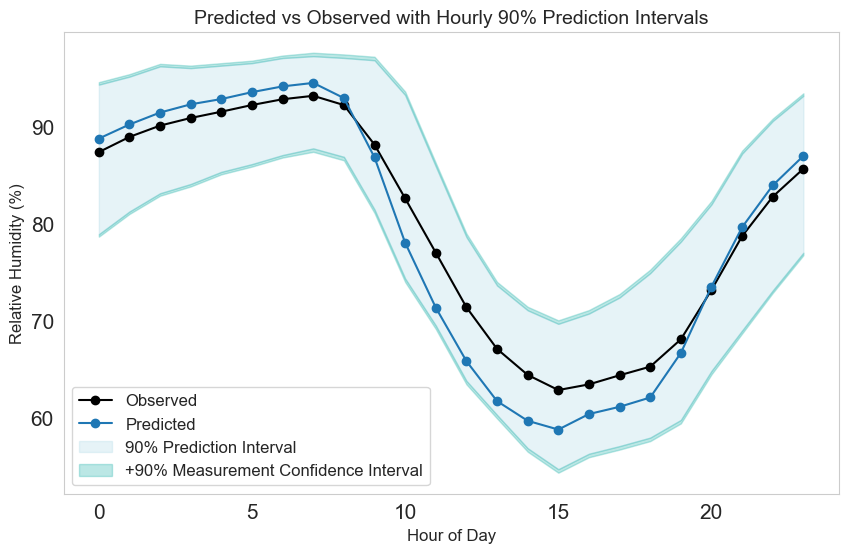

In [56]:
plt.figure(figsize=(10,6))

# Observed mean
plt.plot(hourly_summary['Hour'], hourly_summary['Relative_Humidity'],
         marker='o', color='black', label='Observed')

# Predicted mean
plt.plot(hourly_summary['Hour'], hourly_summary['Predicted_Relative_Humidity'],
         marker='o', color='tab:blue', label='Predicted')

# Fixed hourly prediction interval band
plt.fill_between(hourly_summary['Hour'],
                 hourly_summary['PI_lower'],
                 hourly_summary['PI_upper'],
                 color='lightblue', alpha=0.3,
                 label='90% Prediction Interval')

plt.fill_between(hourly_summary['Hour'],
                 hourly_summary['PI_upper'],
                 hourly_summary['Measurement_CI_upper'],
                 color='lightseagreen', alpha=0.3,
                 label='+90% Measurement Confidence Interval')

plt.fill_between(hourly_summary['Hour'],
                 hourly_summary['Measurement_CI_lower'],
                 hourly_summary['PI_lower'],
                 color='lightseagreen', alpha=0.3,)
                 #label='+90% Measurement Confidence Interval')

plt.xlabel('Hour of Day', fontsize=12)
plt.ylabel('Relative Humidity (%)', fontsize=12)
plt.title('Predicted vs Observed with Hourly 90% Prediction Intervals', fontsize=14)
#plt.grid(True, linestyle='--', alpha=0.6)
plt.grid(False)
plt.legend()

plt.tick_params(axis='both', which='both',color='black', )
plt.savefig(f'results/rh_hourly_perf_{to_train_on}.png',transparent=True)
hourly_summary.to_csv(f'results/RH_hourly_summary_{to_train_on}.csv', index = False)